<a href="https://colab.research.google.com/github/salimkhaskhoussy/deep-learning-projects/blob/main/classificateur_chiens_chats_keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet : Classification de Chiens et Chats à l'aide d'un CNN (Convolutional Neural Network)

Ce projet implémente un réseau de neurones convolutif pour classer automatiquement des images de chats et de chiens à l'aide de TensorFlow et Keras.

In [ ]:
!pip install kagglehub

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")

print("Path to dataset files:", path)

100%|██████████| 775M/775M [00:05<00:00, 143MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1


Nombre total d'images trouvées : 24998


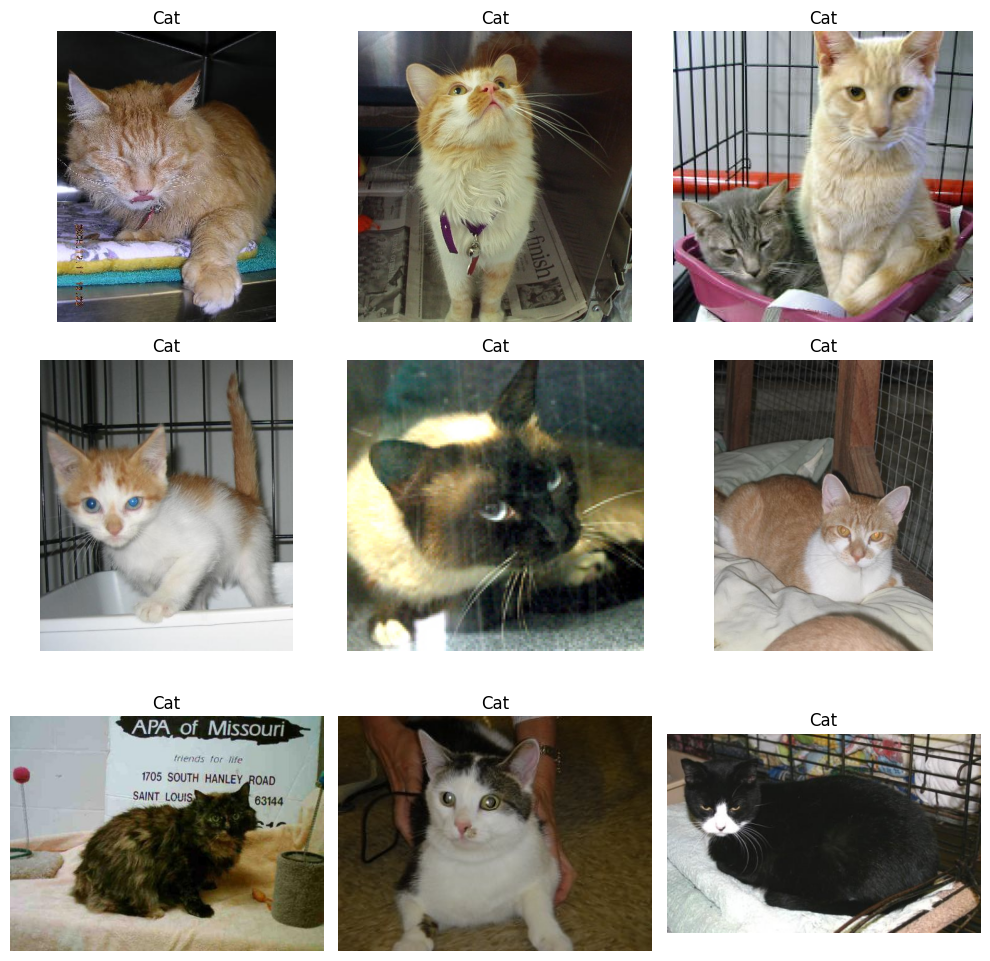

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

# Définir le chemin d'accès contenant les images
dataset_dir = path

# Lister récursivement tous les fichiers d'images (jpg, jpeg, png)
image_paths = []
for root, dirs, files in os.walk(dataset_dir):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            image_paths.append(os.path.join(root, file))

print(f"Nombre total d'images trouvées : {len(image_paths)}")

# Sélectionner un échantillon de 9 images à afficher
sample_images = image_paths[:9] if len(image_paths) >= 9 else image_paths

# Configurer l'affichage avec matplotlib
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.ravel()

for idx, img_path in enumerate(sample_images):
    try:
        img = Image.open(img_path)
        axes[idx].imshow(img)
        # Extraire le nom du dossier parent (souvent la classe de l'image, ex: 'cats' ou 'dogs')
        label = os.path.basename(os.path.dirname(img_path))
        axes[idx].set_title(label)
        axes[idx].axis('off')
    except Exception as e:
        axes[idx].set_title("Erreur de chargement")
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

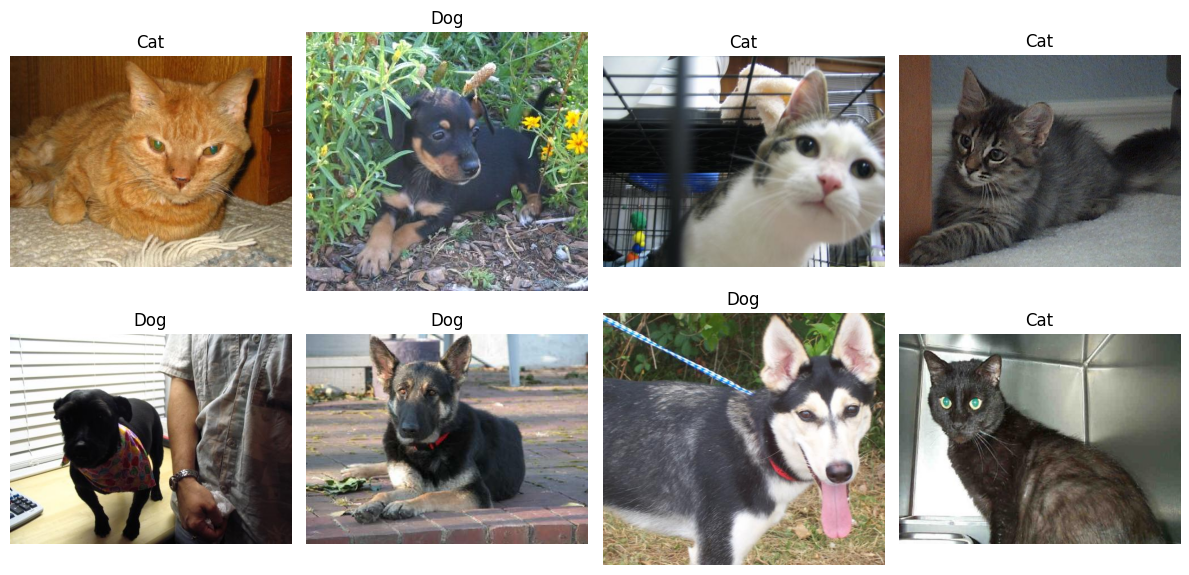

In [ ]:
import random

# Filtrer les images par classe (Cat et Dog)
cat_images = [img for img in image_paths if 'PetImages/Cat' in img or 'PetImages\\Cat' in img]
dog_images = [img for img in image_paths if 'PetImages/Dog' in img or 'PetImages\\Dog' in img]

# Sélectionner de manière aléatoire 4 chats et 4 chiens
random.seed(42) # Pour la reproductibilité
sample_cats = random.sample(cat_images, min(4, len(cat_images)))
sample_dogs = random.sample(dog_images, min(4, len(dog_images)))

# Combiner et mélanger le tout
mixed_samples = sample_cats + sample_dogs
random.shuffle(mixed_samples)

# Configurer l'affichage avec matplotlib (8 images au total dans une grille 2x4)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.ravel()

for idx, img_path in enumerate(mixed_samples):
    try:
        img = Image.open(img_path)
        axes[idx].imshow(img)
        label = os.path.basename(os.path.dirname(img_path))
        axes[idx].set_title(label)
        axes[idx].axis('off')
    except Exception as e:
        axes[idx].set_title("Erreur de chargement")
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
print(f"Nombre d'images de chats (Cat) : {len(cat_images)}")
print(f"Nombre d'images de chiens (Dog) : {len(dog_images)}")
print(f"Total général : {len(cat_images) + len(dog_images)}")

Nombre d'images de chats (Cat) : 12499
Nombre d'images de chiens (Dog) : 12499
Total général : 24998


In [ ]:
import shutil
from sklearn.model_selection import train_test_split

# Définir le répertoire de destination pour notre structure de données
base_dir = '/content/dataset_structured'
os.makedirs(base_dir, exist_ok=True)

# Créer les dossiers pour l'entraînement et la validation
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')

for folder in [train_dir, val_dir]:
    os.makedirs(os.path.join(folder, 'Cat'), exist_ok=True)
    os.makedirs(os.path.join(folder, 'Dog'), exist_ok=True)

# Diviser les images (80% train, 20% validation) pour chaque classe
cat_train, cat_val = train_test_split(cat_images, test_size=0.2, random_state=42)
dog_train, dog_val = train_test_split(dog_images, test_size=0.2, random_state=42)

def copy_images(image_list, destination_folder):
    copied_count = 0
    for img_path in image_list:
        try:
            # Vérifier si l'image n'est pas corrompue en essayant de l'ouvrir
            with Image.open(img_path) as img:
                img.verify()
            # Copier l'image si elle est valide
            shutil.copy(img_path, destination_folder)
            copied_count += 1
        except Exception:
            # Ignorer l'image si elle est corrompue
            continue
    return copied_count

# Copier les fichiers vers la nouvelle structure
print("Copie des images de chats en cours...")
num_cat_train = copy_images(cat_train, os.path.join(train_dir, 'Cat'))
num_cat_val = copy_images(cat_val, os.path.join(val_dir, 'Cat'))

print("Copie des images de chiens en cours...")
num_dog_train = copy_images(dog_train, os.path.join(train_dir, 'Dog'))
num_dog_val = copy_images(dog_val, os.path.join(val_dir, 'Dog'))

print("\nStructure des dossiers créée avec succès !")
print(f"Entraînement : {num_cat_train} chats, {num_dog_train} chiens")
print(f"Validation : {num_cat_val} chats, {num_dog_val} chiens")

Copie des images de chats en cours...
Copie des images de chiens en cours...


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))



Structure des dossiers créée avec succès !
Entraînement : 9999 chats, 9999 chiens
Validation : 2500 chats, 2500 chiens


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models

# Configuration des paramètres
BATCH_SIZE = 32
IMG_SIZE = (150, 150)
EPOCHS = 5

# Création des générateurs de données avec normalisation (rescale)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

# Définition de l'architecture du modèle CNN
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

Found 19998 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,034,177 (72.61 MB)

 Trainable params: 19,034,177 (72.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
import os
import shutil
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from PIL import Image

# Configuration des chemins
EPOCHS = 5
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
base_dir = '/content/dataset_structured'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')

# Définir l'emplacement absolu du dataset téléchargé par kagglehub
dataset_dir = '/root/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1'
if not os.path.exists(dataset_dir):
    # Solution de repli dynamique si le chemin complet diffère légèrement
    import kagglehub
    dataset_dir = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")

# Toujours s'assurer que les dossiers de destination existent
os.makedirs(base_dir, exist_ok=True)
for folder in [train_dir, val_dir]:
    os.makedirs(os.path.join(folder, 'Cat'), exist_ok=True)
    os.makedirs(os.path.join(folder, 'Dog'), exist_ok=True)

# Vérifier si les dossiers contiennent déjà des images, sinon on les copie
cat_train_len = len(os.listdir(os.path.join(train_dir, 'Cat')))
dog_train_len = len(os.listdir(os.path.join(train_dir, 'Dog')))

if cat_train_len == 0 or dog_train_len == 0:
    print("Détection d'un dossier vide. Copie et filtrage des images d'origine en cours...")

    # Scan complet des fichiers d'images
    image_paths = []
    for root, dirs, files in os.walk(dataset_dir):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_paths.append(os.path.join(root, file))

    cat_images = [img for img in image_paths if 'PetImages/Cat' in img or 'PetImages\\Cat' in img or '/Cat/' in img]
    dog_images = [img for img in image_paths if 'PetImages/Dog' in img or 'PetImages\\Dog' in img or '/Dog/' in img]

    print(f"Trouvé : {len(cat_images)} chats et {len(dog_images)} chiens originaux.")

    cat_train, cat_val = train_test_split(cat_images, test_size=0.2, random_state=42)
    dog_train, dog_val = train_test_split(dog_images, test_size=0.2, random_state=42)

    def copy_images(image_list, destination_folder):
        copied_count = 0
        for img_path in image_list:
            try:
                with Image.open(img_path) as img:
                    img.verify()
                shutil.copy(img_path, destination_folder)
                copied_count += 1
            except Exception:
                continue
        return copied_count

    copy_images(cat_train, os.path.join(train_dir, 'Cat'))
    copy_images(cat_val, os.path.join(val_dir, 'Cat'))
    copy_images(dog_train, os.path.join(train_dir, 'Dog'))
    copy_images(dog_val, os.path.join(val_dir, 'Dog'))
    print("Images copiées et structurées avec succès.")

# Configuration des générateurs
print("Configuration des générateurs de données...")
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)
val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

# Définition et compilation du modèle
if 'model' not in globals():
    print("Initialisation du modèle CNN...")
    model = models.Sequential([
        layers.Input(shape=(150, 150, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),

        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        loss='binary_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

# Lancement de l'entraînement
history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator
)

Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
Détection d'un dossier vide. Copie et filtrage des images d'origine en cours...
Trouvé : 12499 chats et 12499 chiens originaux.


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Images copiées et structurées avec succès.
Configuration des générateurs de données...
Found 19998 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1236s 2s/step - accuracy: 0.5746 - loss: 0.6783 - val_accuracy: 0.6850 - val_loss: 0.6119
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1240s 2s/step - accuracy: 0.7051 - loss: 0.5801 - val_accuracy: 0.7638 - val_loss: 0.4899
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1230s 2s/step - accuracy: 0.7525 - loss: 0.5058 - val_accuracy: 0.7896 - val_loss: 0.4611
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1216s 2s/step - accuracy: 0.7858 - loss: 0.4573 - val_accuracy: 0.8220 - val_loss: 0.4049
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 1211s 2s/step - accuracy: 0.8054 - loss: 0.4213 - val_accuracy: 0.8356 - val_loss: 0.3955


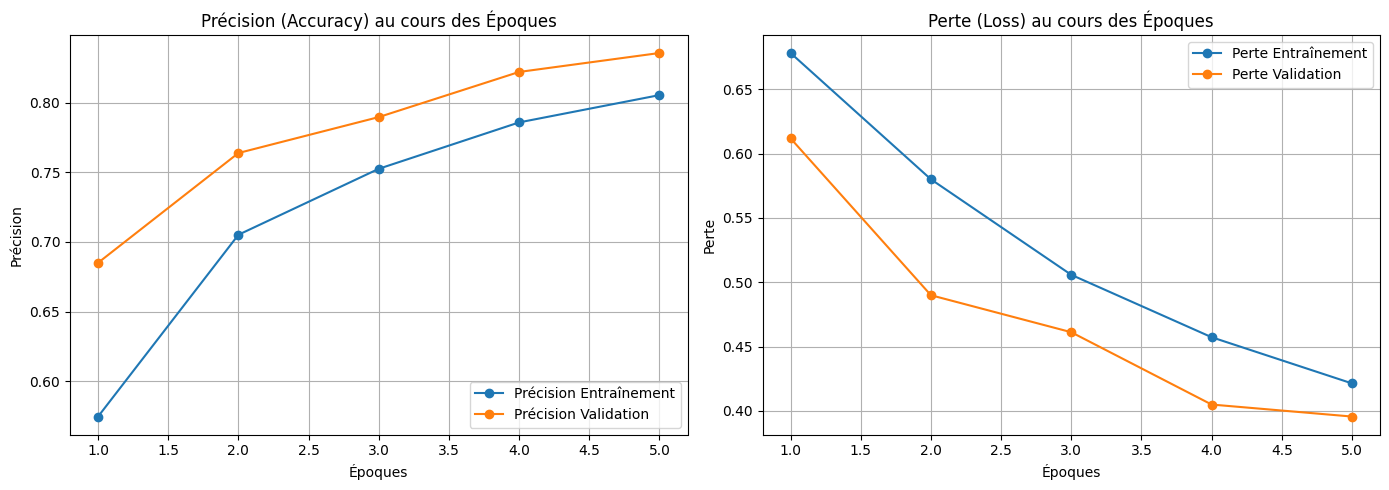

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# --- 1. COURBES D'APPRENTISSAGE ---
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Graphe de la précision
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Précision Entraînement', marker='o')
plt.plot(epochs_range, val_acc, label='Précision Validation', marker='o')
plt.title('Précision (Accuracy) au cours des Époques')
plt.xlabel('Époques')
plt.ylabel('Précision')
plt.legend(loc='lower right')
plt.grid(True)

# Graphe de la perte
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Perte Entraînement', marker='o')
plt.plot(epochs_range, val_loss, label='Perte Validation', marker='o')
plt.title('Perte (Loss) au cours des Époques')
plt.xlabel('Époques')
plt.ylabel('Perte')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

Re-création propre du générateur de validation (sans mélange)...
Found 5000 images belonging to 2 classes.
Génération des prédictions...
148/157 ━━━━━━━━━━━━━━━━━━━━ 4s 449ms/step

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


157/157 ━━━━━━━━━━━━━━━━━━━━ 70s 445ms/step


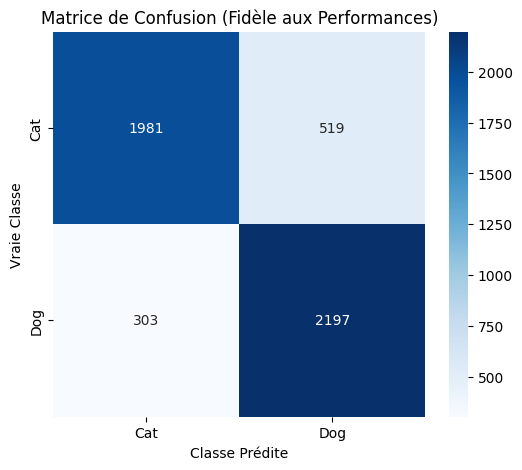


Rapport de classification détaillé :

              precision    recall  f1-score   support

         Cat       0.87      0.79      0.83      2500
         Dog       0.81      0.88      0.84      2500

    accuracy                           0.84      5000
   macro avg       0.84      0.84      0.84      5000
weighted avg       0.84      0.84      0.84      5000



In [10]:
# --- 2. MATRICE DE CONFUSION (CORRIGÉE) ---
print("Re-création propre du générateur de validation (sans mélange)...")

# Recréer le générateur de validation avec shuffle=False dès l'initialisation
eval_datagen = ImageDataGenerator(rescale=1./255)
eval_generator = eval_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False  # Crucial pour garder l'alignement
)

print("Génération des prédictions...")
y_pred_probs = model.predict(eval_generator)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()
y_true = eval_generator.classes
class_names = list(eval_generator.class_indices.keys())

# Calcul de la matrice de confusion
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

# Affichage de la matrice de confusion
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de Confusion (Fidèle aux Performances)')
plt.ylabel('Vraie Classe')
plt.xlabel('Classe Prédite')
plt.show()

# Affichage du rapport de classification détaillé
print("\nRapport de classification détaillé :\n")
print(classification_report(y_true, y_pred, target_names=class_names))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step


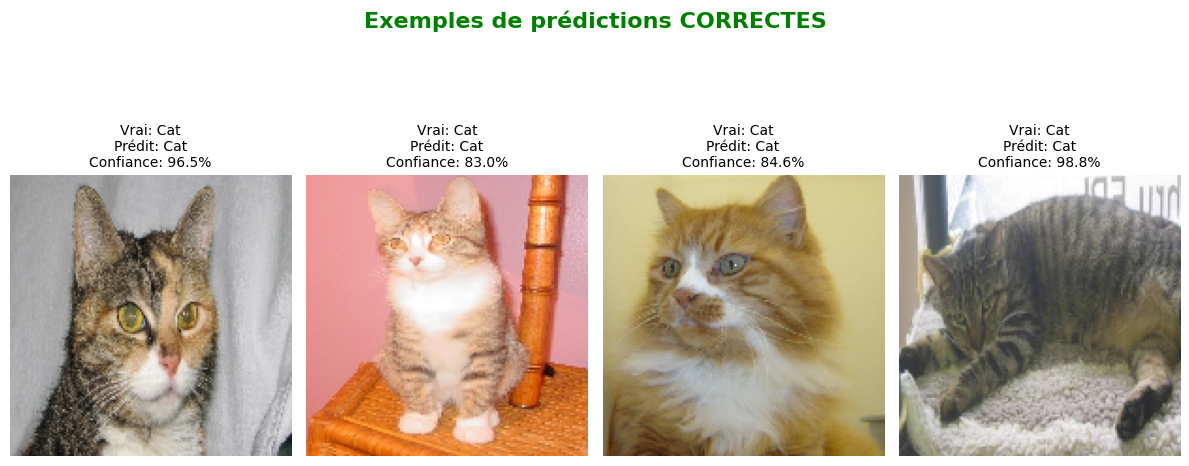

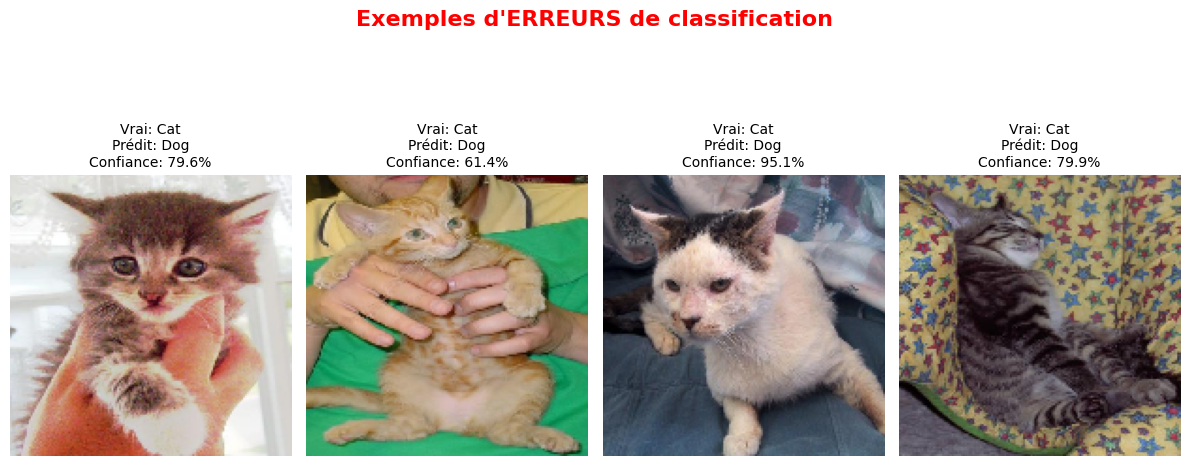

In [11]:
# --- 3. VISUALISATION DES PRÉDICTIONS (CORRECTES VS ERREURS) ---
import numpy as np
import matplotlib.pyplot as plt

# Obtenir un lot complet d'images et leurs vraies étiquettes
x_val, y_val_true = next(eval_generator)
y_val_pred_probs = model.predict(x_val)
y_val_pred = (y_val_pred_probs > 0.5).astype(int).flatten()
y_val_true = y_val_true.astype(int)

# Identifier les index des prédictions correctes et des erreurs
correct_indices = np.where(y_val_pred == y_val_true)[0]
incorrect_indices = np.where(y_val_pred != y_val_true)[0]

# Inverser le dictionnaire des classes pour obtenir les noms
labels_map = {v: k for k, v in eval_generator.class_indices.items()}

# 1. Afficher quelques prédictions correctes
plt.figure(figsize=(12, 6))
plt.suptitle("Exemples de prédictions CORRECTES", fontsize=16, weight='bold', color='green')
for i, idx in enumerate(correct_indices[:4]):
    plt.subplot(1, 4, i + 1)
    plt.imshow(x_val[idx])
    true_label = labels_map[y_val_true[idx]]
    pred_label = labels_map[y_val_pred[idx]]
    confidence = y_val_pred_probs[idx][0] if y_val_pred[idx] == 1 else 1 - y_val_pred_probs[idx][0]
    plt.title(f"Vrai: {true_label}\nPrédit: {pred_label}\nConfiance: {confidence:.1%}", fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

# 2. Afficher quelques erreurs (si présentes dans le lot)
if len(incorrect_indices) > 0:
    plt.figure(figsize=(12, 6))
    plt.suptitle("Exemples d'ERREURS de classification", fontsize=16, weight='bold', color='red')
    for i, idx in enumerate(incorrect_indices[:4]):
        plt.subplot(1, 4, i + 1)
        plt.imshow(x_val[idx])
        true_label = labels_map[y_val_true[idx]]
        pred_label = labels_map[y_val_pred[idx]]
        confidence = y_val_pred_probs[idx][0] if y_val_pred[idx] == 1 else 1 - y_val_pred_probs[idx][0]
        plt.title(f"Vrai: {true_label}\nPrédit: {pred_label}\nConfiance: {confidence:.1%}", fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Aucune erreur détectée dans ce lot d'images !")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


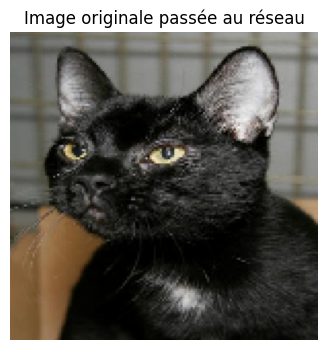

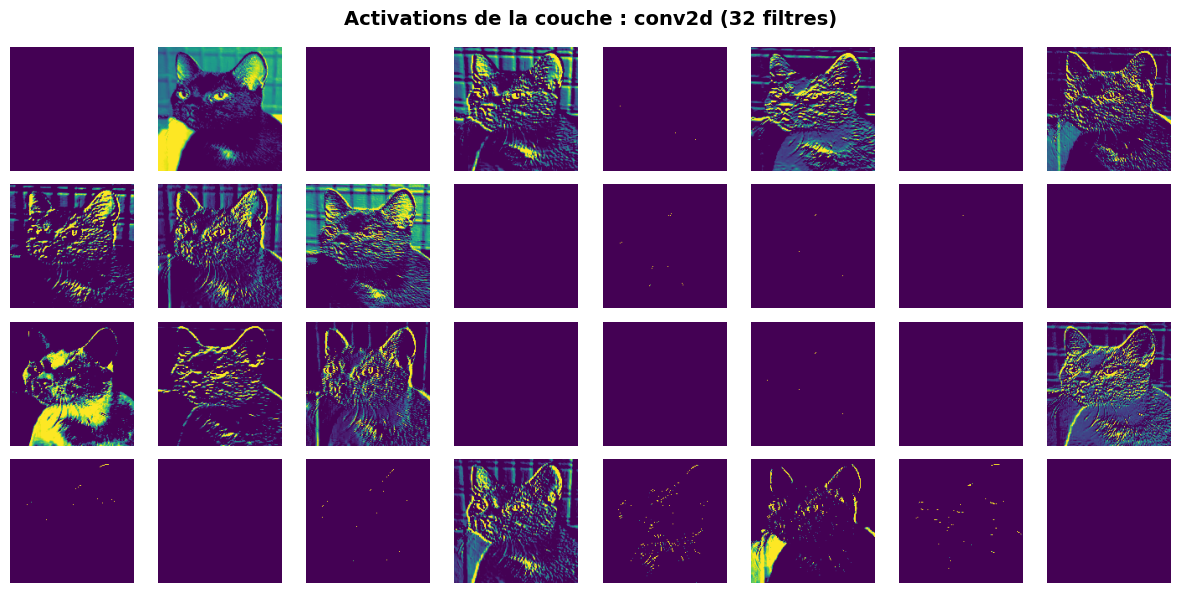

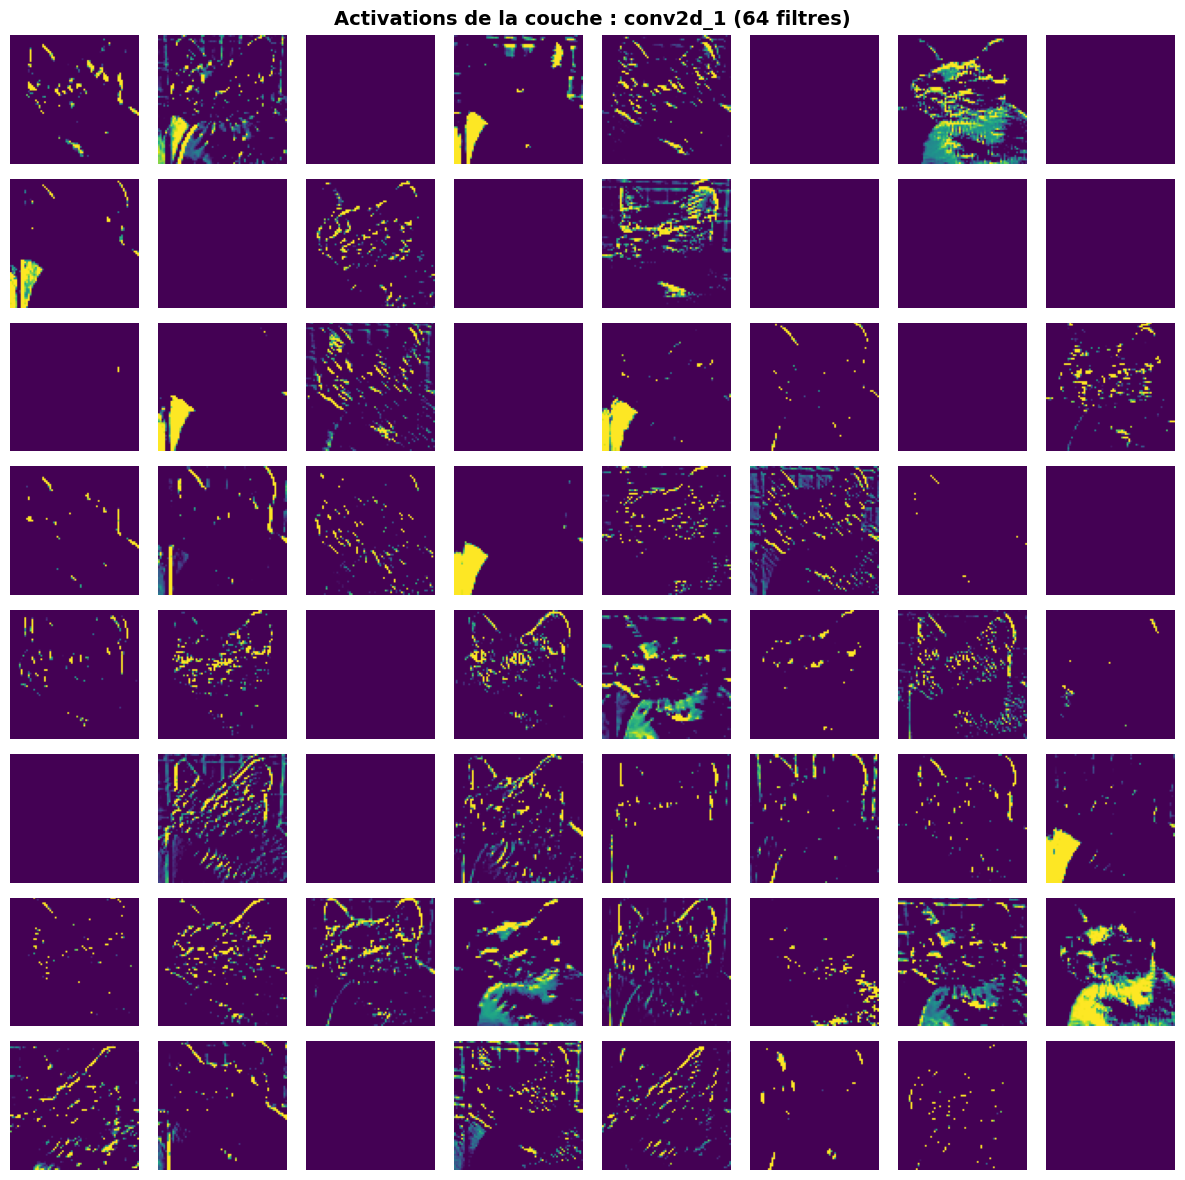

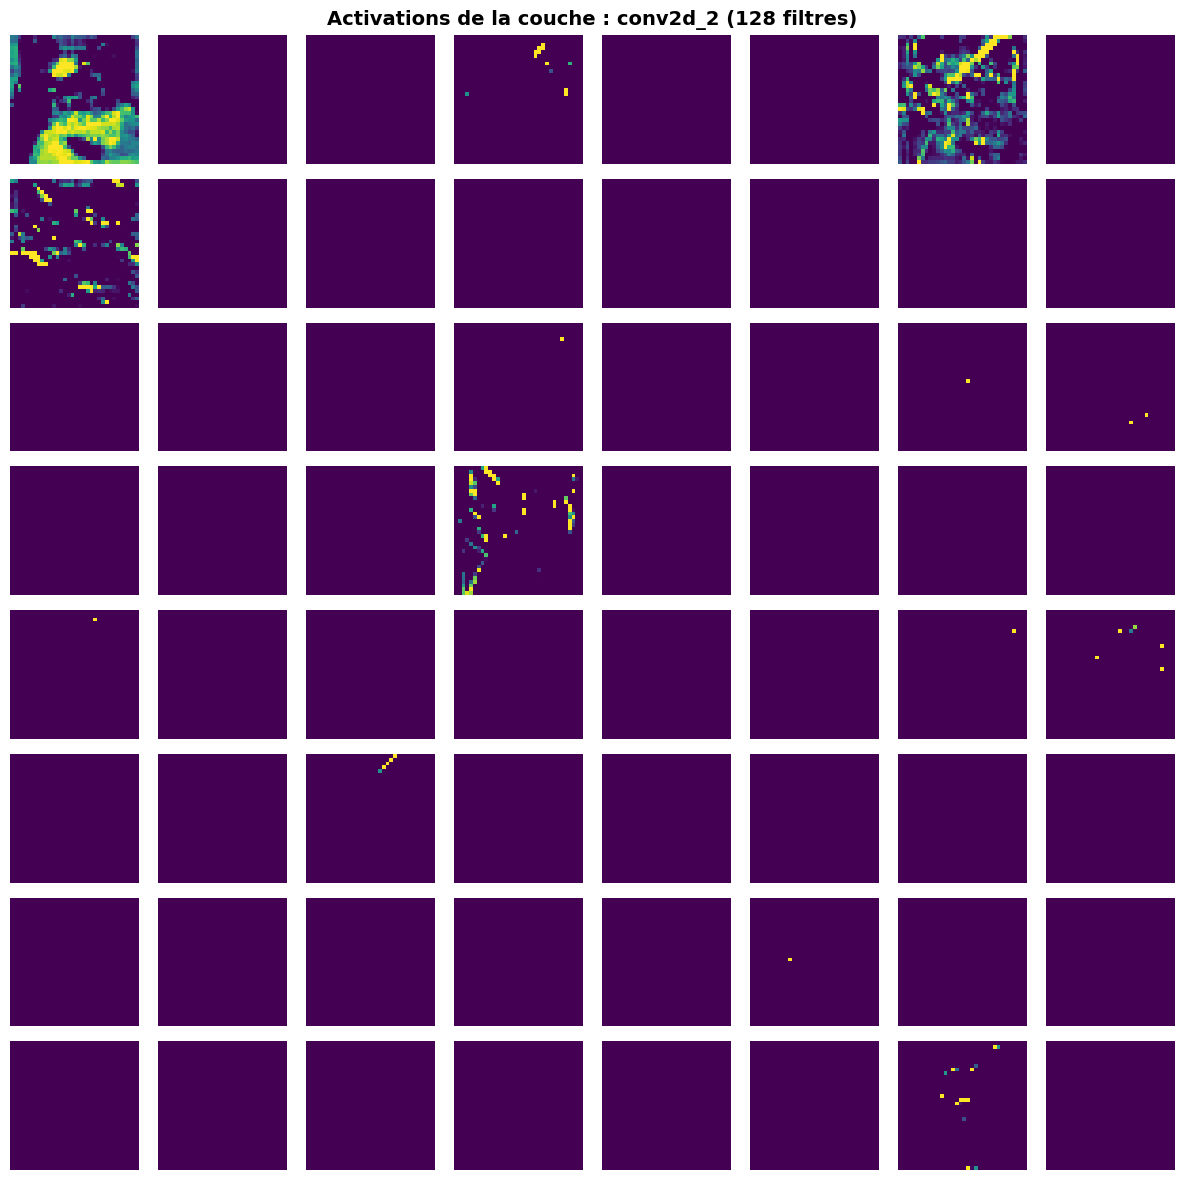

In [13]:
# --- 4. VISUALISATION DES CARTES D'ACTIVATION (FEATURE MAPS - CORRIGÉ) ---
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras import layers

# 1. Sélectionner une image de test du générateur de validation
x_sample, _ = next(eval_generator)
single_img = x_sample[0]  # On prend la première image du lot
img_tensor = np.expand_dims(single_img, axis=0) # Ajouter la dimension batch (1, 150, 150, 3)

# Appeler le modèle une fois sur l'image pour s'assurer qu'il est construit et initialisé
_ = model(img_tensor)

# 2. Récupérer les sorties des couches de convolution
conv_layer_outputs = [layer.output for layer in model.layers if isinstance(layer, layers.Conv2D)]

# Créer un modèle intermédiaire qui renvoie ces activations
activation_model = Model(inputs=model.inputs, outputs=conv_layer_outputs)
activations = activation_model.predict(img_tensor)

if not isinstance(activations, list):
    activations = [activations]

# 3. Afficher l'image originale
plt.figure(figsize=(4, 4))
plt.imshow(single_img)
plt.title("Image originale passée au réseau")
plt.axis('off')
plt.show()

# 4. Afficher les cartes de caractéristiques pour chaque couche de convolution
layer_names = [layer.name for layer in model.layers if isinstance(layer, layers.Conv2D)]

for layer_name, layer_activation in zip(layer_names, activations):
    n_features = layer_activation.shape[-1]
    n_cols = min(8, n_features)
    n_rows = (min(64, n_features) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.5, n_rows * 1.5))
    fig.suptitle(f"Activations de la couche : {layer_name} ({n_features} filtres)", fontsize=14, weight='bold')

    axes = axes.ravel() if isinstance(axes, np.ndarray) else [axes]

    for idx in range(len(axes)):
        if idx < n_features:
            channel_image = layer_activation[0, :, :, idx]

            # Normalisation pour un meilleur rendu visuel
            channel_image -= channel_image.mean()
            if channel_image.std() > 0:
                channel_image /= channel_image.std()
            channel_image *= 64
            channel_image += 128
            channel_image = np.clip(channel_image, 0, 255).astype('uint8')

            axes[idx].imshow(channel_image, cmap='viridis')
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

## 5. Sauvegarde et Chargement du Modèle (Fichier .keras)

Pour pouvoir réutiliser notre modèle entraîné sans avoir à le réentraîner à chaque fois, nous le sauvegardons dans un fichier au format standardisé `.keras`. Nous montrons également comment charger ce fichier pour faire une prédiction.

In [14]:
import tensorflow as tf
from tensorflow.keras.models import load_model
import numpy as np

# --- SAUVEGARDE DU MODÈLE ---
model_filename = 'classificateur_chiens_chats.keras'
model.save(model_filename)
print(f"Modèle sauvegardé avec succès dans le fichier : '{model_filename}'")

# --- CHARGEMENT DU MODÈLE ---
# Pour simuler l'appel ultérieur ou dans un autre script, on recharge le fichier
modele_charge = load_model(model_filename)
print("Modèle rechargé avec succès depuis le fichier !")

Modèle sauvegardé avec succès dans le fichier : 'classificateur_chiens_chats.keras'
Modèle rechargé avec succès depuis le fichier !


### Exemple d'utilisation sur une nouvelle image d'évaluation

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step


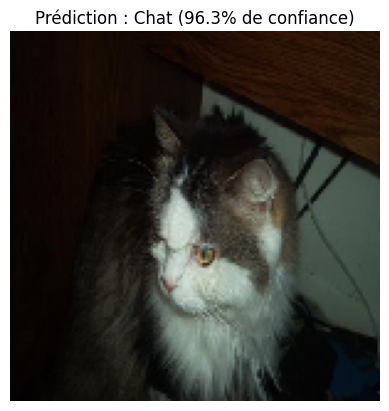

In [15]:
# Prendre une image exemple du générateur de validation
x_sample, y_sample = next(eval_generator)
image_test = x_sample[0]

# Préparation de l'image (ajouter la dimension Batch: (1, 150, 150, 3))
image_pred_input = np.expand_dims(image_test, axis=0)

# Faire la prédiction avec le modèle chargé depuis le fichier
prediction_prob = modele_charge.predict(image_pred_input)[0][0]
classe_predite = 'Chien' if prediction_prob > 0.5 else 'Chat'
confiance = prediction_prob if prediction_prob > 0.5 else 1 - prediction_prob

# Affichage du résultat
import matplotlib.pyplot as plt
plt.imshow(image_test)
plt.title(f"Prédiction : {classe_predite} ({confiance:.1%} de confiance)")
plt.axis('off')
plt.show()